# Project D: Collaboration Networks (RQ3, network part)

**Owner role:** Collaboration Networks (co-authorship and institution networks, bibliometric maps, community detection, centrality).

**Question:** Which European institutions and countries sit at the centre of AI-in-education collaboration, and do institutions form one collaboration community or several?

**Method in one paragraph.** Nodes are EU institutions. Two institutions are linked when they appear together on at least one candidate paper; the link weight is the number of shared papers. We compute centrality, detect communities with the Louvain algorithm (weighted, `seed=42`), and compare the communities with a *just-country* baseline (partition of the same network by country). A sensitivity analysis checks whether the picture survives removing likely off-topic papers and very large multi-author papers.

Input: `eu_paper_institution_affiliations.csv` and `openalex_relevance_screened.csv` from `project-d/data/processed/`.

In [1]:
import itertools
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import louvain_communities, modularity
from sklearn.metrics import normalized_mutual_info_score as nmi

# Set to your local project-d folder (or the cloned repo)
PROJECT = Path("project-d")
P = PROJECT / "data" / "processed"
OUT = P / "deliverables"; OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

aff = pd.read_csv(P / "eu_paper_institution_affiliations.csv").drop_duplicates(["openalex_id", "institution_id"])
screened = pd.read_csv(P / "openalex_relevance_screened.csv")
info = aff.drop_duplicates("institution_id").set_index("institution_id")
country = info["country_code"].to_dict()
iname = info["institution"].to_dict()
print("paper-institution links:", len(aff), "| papers:", aff.openalex_id.nunique(), "| institutions:", aff.institution_id.nunique())

paper-institution links: 13879 | papers: 7594 | institutions: 2489


## 1. Build the co-authorship network

Papers with a single EU institution add a node but no link. Duplicate paper-institution pairs were dropped first (10 rows).

In [2]:
def build_graph(links):
    w = Counter()
    for pid, g in links.groupby("openalex_id"):
        ids = sorted(set(g.institution_id))
        for u, v in itertools.combinations(ids, 2):
            w[(u, v)] += 1
    G = nx.Graph()
    G.add_nodes_from(links.institution_id.unique())
    G.add_weighted_edges_from([(u, v, c) for (u, v), c in w.items()])
    return G

def summarize(G):
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    H = G.subgraph(comps[0]).copy()
    com = louvain_communities(H, weight="weight", seed=SEED)
    by_c = {}
    for n in H: by_c.setdefault(country[n], set()).add(n)
    lab_com = {n: i for i, c in enumerate(com) for n in c}
    tw = sum(d["weight"] for *_, d in H.edges(data=True))
    cross = sum(d["weight"] for u, v, d in H.edges(data=True) if country[u] != country[v]) / tw
    return dict(nodes=G.number_of_nodes(), edges=G.number_of_edges(), density=nx.density(G),
                components=len(comps), isolates=sum(len(c) == 1 for c in comps),
                largest=len(H), largest_share=len(H) / G.number_of_nodes(),
                communities=len(com), big_communities=sum(len(c) >= 30 for c in com),
                modularity=modularity(H, com, weight="weight"),
                modularity_country=modularity(H, list(by_c.values()), weight="weight"),
                nmi_country=nmi([lab_com[n] for n in H], [country[n] for n in H]),
                cross_country_share=cross), H, com

G = build_graph(aff)
main, H, com = summarize(G)
pd.Series(main).to_frame("value")

,value
nodes,2489.000000
edges,13408.000000
density,0.004330
components,319.000000
isolates,279.000000
largest,2124.000000
largest_share,0.853355
communities,17.000000
big_communities,14.000000
modularity,0.589870


## 2. Centrality

Measured on the largest connected component. *Weighted degree* is the total number of shared-paper links, *degree* the number of distinct partners, and *betweenness* (approximated from 500 sampled nodes, `seed=42`) shows which institutions bridge otherwise separate groups.

In [3]:
wdeg = dict(H.degree(weight="weight")); deg = dict(H.degree())
btw = nx.betweenness_centrality(H, k=500, seed=SEED)
lab_com = {n: i for i, c in enumerate(sorted(com, key=len, reverse=True)) for n in c}
cent = pd.DataFrame({"institution": [iname[n] for n in H], "country": [country[n] for n in H],
                     "degree": [deg[n] for n in H], "weighted_degree": [wdeg[n] for n in H],
                     "betweenness": [round(btw[n], 4) for n in H], "community": [lab_com[n] + 1 for n in H]})
papers_per_inst = aff.groupby("institution_id").openalex_id.nunique()
cent["papers"] = [papers_per_inst[n] for n in H]
cent = cent.sort_values("weighted_degree", ascending=False).reset_index(drop=True)
cent.to_csv(OUT / "network_centrality.csv", index=False)
print("Top 10 by weighted degree"); display(cent.head(10))
print("Top 10 by betweenness"); display(cent.sort_values("betweenness", ascending=False).head(10).reset_index(drop=True))

Top 10 by weighted degree


,institution,country,degree,weighted_degree,betweenness,community,papers
0,Centre National de la Recherche Scientifique,FR,263,455,0.1109,1,93
1,Inserm,FR,193,304,0.0504,1,42
2,Ludwig-Maximilians-Universität München,DE,156,220,0.0401,4,71
3,University of Bonn,DE,69,210,0.0086,12,86
4,Sorbonne Université,FR,99,187,0.0166,1,38
5,Karolinska Institutet,SE,132,184,0.0309,5,41
6,Technical University of Munich,DE,116,173,0.0299,2,78
7,Vrije Universiteit Amsterdam,NL,99,171,0.0134,3,42
8,University of Tübingen,DE,83,169,0.0155,2,63
9,Leibniz University Hannover,DE,27,148,0.0039,12,80


Top 10 by betweenness


,institution,country,degree,weighted_degree,betweenness,community,papers
0,Centre National de la Recherche Scientifique,FR,263,455,0.1109,1,93
1,Inserm,FR,193,304,0.0504,1,42
2,Ludwig-Maximilians-Universität München,DE,156,220,0.0401,4,71
3,Karolinska Institutet,SE,132,184,0.0309,5,41
4,Technical University of Munich,DE,116,173,0.0299,2,78
5,University of Bologna,IT,79,93,0.0275,3,48
6,National and Kapodistrian University of Athens,GR,96,119,0.0272,9,43
7,Universidade do Porto,PT,71,89,0.0268,6,46
8,University of Bari Aldo Moro,IT,86,114,0.0260,3,51
9,University of Copenhagen,DK,82,129,0.0253,11,52


**What the network shows**

- **Shape.** 2,489 institutions are linked by 13,408 collaboration links (density 0.4%). 279 institutions never appear with another EU institution on a paper, and the largest connected component holds 2,124 institutions (85.3%). So most of the field is one connected network, with a fringe of isolated institutions.
- **Centre.** CNRS is the clear hub: 455 weighted links to 263 partners and the highest betweenness (0.11, more than twice the next institution). Inserm (304), LMU Munich (220), University of Bonn (210) and Sorbonne Université (187) follow. Bonn and Hannover have high weighted degree from few partners (69 and 27), which means repeated collaboration between the same institutions, whereas CNRS and Inserm link to many different partners.
- **Bridges.** Betweenness picks out institutions that tie regions together: CNRS, Inserm, LMU Munich, Karolinska Institutet and TU Munich, then Bologna, Athens, Porto, Bari and Copenhagen, which connect their own national clusters to the rest.
- **Reading caution.** Inserm, Karolinska Institutet and the Charité are medical institutions. They suggest that some health-science papers from the broad keyword search are in the candidate set. The same hubs stay on top when only "Likely relevant" papers are used (section 5), but the keyword screen is weak, so this is a limitation of the data.

## 3. Communities

Louvain communities in the largest component, ranked by size. *Purity* is the share of members from the community's most common country.

In [4]:
rows = []
for i, c in enumerate(sorted(com, key=len, reverse=True), start=1):
    cn = Counter(country[n] for n in c)
    top = cn.most_common(3)
    hubs = sorted(c, key=lambda n: wdeg[n], reverse=True)[:3]
    rows.append({"community": i, "institutions": len(c), "top_country": top[0][0],
                 "purity": round(top[0][1] / len(c), 2),
                 "top_3_countries": ", ".join(f"{k} {v}" for k, v in top),
                 "countries": len(cn), "hubs": "; ".join(iname[h] for h in hubs)})
comm = pd.DataFrame(rows)
comm.to_csv(OUT / "network_communities.csv", index=False)
comm

,community,institutions,top_country,purity,top_3_countries,countries,hubs
0,1,302,FR,0.90,"FR 271, PT 9, DE 7",10,Centre National de la Recherche Scientifique; ...
1,2,300,DE,0.75,"DE 226, AT 12, FR 12",18,Technical University of Munich; University of ...
2,3,298,IT,0.61,"IT 181, DE 30, FR 18",22,Vrije Universiteit Amsterdam; University of Na...
3,4,224,NL,0.32,"NL 71, ES 43, DE 24",20,Ludwig-Maximilians-Universität München; Amster...
4,5,168,FI,0.23,"FI 38, BE 27, SE 21",19,Karolinska Institutet; University of Eastern F...
5,6,147,PT,0.71,"PT 104, ES 25, PL 4",10,Universidade do Porto; University of Lisbon; U...
6,7,146,ES,0.67,"ES 98, BG 12, FR 7",13,Universidad Complutense de Madrid; Universidad...
7,8,130,PL,0.47,"PL 61, CZ 17, LT 8",20,Czech Technical University in Prague; Universi...
8,9,127,GR,0.47,"GR 60, FR 18, IT 10",17,National and Kapodistrian University of Athens...
9,10,68,RO,0.65,"RO 44, FR 8, DE 3",11,Universitatea Națională de Știință și Tehnolog...


## 4. Communities versus country (baseline)

If collaboration were just national, a partition by country would explain the network as well as Louvain does. Compare the two partitions on the same graph.

In [5]:
base = pd.DataFrame({
    "measure": ["Modularity of Louvain communities", "Modularity of country partition (baseline)",
                "Normalised mutual information (communities vs country)",
                "Share of link weight that crosses country borders"],
    "value": [main["modularity"], main["modularity_country"], main["nmi_country"], main["cross_country_share"]]}).round(3)
base

,measure,value
0,Modularity of Louvain communities,0.590
1,Modularity of country partition (baseline),0.500
2,Normalised mutual information (communities vs ...,0.465
3,Share of link weight that crosses country borders,0.383


In [6]:
# Country-level collaboration network (links between countries, counting shared papers)
cw = Counter()
for pid, g in aff.groupby("openalex_id"):
    cs = sorted(set(g.country_code))
    for u, v in itertools.combinations(cs, 2): cw[(u, v)] += 1
cpairs = pd.DataFrame([(u, v, c) for (u, v), c in cw.items()], columns=["country_a", "country_b", "joint_papers"]) \
           .sort_values("joint_papers", ascending=False).reset_index(drop=True)
cpairs.to_csv(OUT / "network_country_pairs.csv", index=False)
cpairs.head(10)

,country_a,country_b,joint_papers
0,DE,IT,76
1,DE,NL,76
2,ES,IT,73
3,DE,ES,65
4,DE,FR,57
5,IT,NL,53
6,AT,DE,51
7,ES,FR,44
8,FR,IT,44
9,ES,NL,42


**Several communities, shaped by country but not only by country**

- Louvain finds 17 communities in the largest component, 14 of them with at least 30 institutions, so the network is **several collaboration communities, not one**.
- Country matters. The French-led community (C1, 302 institutions) is 90% French, the German-led C2 is 75% German, Portugal (C6) 71% and Spain (C7) 67%. C1 is built around CNRS, Inserm and Sorbonne Université.
- Country is not the whole story. The Dutch-led C4 (32% Dutch) and Finnish-led C5 (23% Finnish) mix many countries, including Nordic and Benelux institutions in C5, and C3 is Italian-led (61%) but includes 30 German and 18 French institutions.
- Statistically, the Louvain partition has modularity 0.59, against 0.50 for the partition by country alone, and the mutual information between communities and country is 0.46. 38% of the link weight crosses a national border. The country partition explains a large part of the structure, but the data-driven communities fit the collaboration links better, so collaboration is national-regional rather than purely national.
- The most frequent cross-country pairs are Germany-Italy (76 joint papers), Germany-Netherlands (76) and Spain-Italy (73).

## 5. Sensitivity checks

The candidate set contains off-topic records (the keyword screen is weak), and a few very large papers add many links at once. Three variants are compared with the main network: (a) only papers flagged *Likely relevant*, (b) papers with at most 10 EU institutions, (c) links with weight of at least 2 (repeated collaboration only).

In [7]:
likely = set(screened.loc[screened.automated_relevance_flag == "Likely relevant", "openalex_id"])
n_inst = aff.groupby("openalex_id").institution_id.nunique()
small = set(n_inst[n_inst <= 10].index)

variants = {"main network": aff,
            "(a) likely relevant only": aff[aff.openalex_id.isin(likely)],
            "(b) papers with <= 10 institutions": aff[aff.openalex_id.isin(small)]}
res = {}
tops = {}
for k, links in variants.items():
    Gk = build_graph(links); s, Hk, ck = summarize(Gk); res[k] = s
    wk = dict(Hk.degree(weight="weight")); tops[k] = [iname[n] for n in sorted(wk, key=wk.get, reverse=True)[:5]]
# (c) repeated collaboration: keep edges with weight >= 2
G2 = nx.Graph([(u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= 2]); s2, H2, c2 = summarize(G2)
s2["nodes"] = G2.number_of_nodes(); res["(c) links with weight >= 2"] = s2
w2 = dict(H2.degree(weight="weight")); tops["(c) links with weight >= 2"] = [iname[n] for n in sorted(w2, key=w2.get, reverse=True)[:5]]
sens = pd.DataFrame(res).T[["nodes", "edges", "largest", "largest_share", "communities", "big_communities",
                            "modularity", "modularity_country", "nmi_country", "cross_country_share"]]
sens = sens.astype({"nodes": int, "edges": int, "largest": int, "communities": int, "big_communities": int}).round(3)
sens.to_csv(OUT / "network_sensitivity.csv")
display(sens)
for k, v in tops.items(): print(f"{k}: {', '.join(v)}")

,nodes,edges,largest,largest_share,communities,big_communities,modularity,modularity_country,nmi_country,cross_country_share
main network,2489,13408,2124,0.853,17,14,0.590,0.500,0.465,0.383
(a) likely relevant only,2300,11460,1934,0.841,16,13,0.594,0.498,0.407,0.385
(b) papers with <= 10 institutions,2338,8224,1954,0.836,15,14,0.653,0.567,0.510,0.330
(c) links with weight >= 2,874,2026,735,0.841,17,12,0.747,0.628,0.550,0.241


main network: Centre National de la Recherche Scientifique, Inserm, Ludwig-Maximilians-Universität München, University of Bonn, Sorbonne Université
(a) likely relevant only: Centre National de la Recherche Scientifique, Inserm, University of Bonn, Ludwig-Maximilians-Universität München, University of Tübingen
(b) papers with <= 10 institutions: Centre National de la Recherche Scientifique, University of Bonn, Inserm, Leibniz University Hannover, Technical University of Munich
(c) links with weight >= 2: Centre National de la Recherche Scientifique, University of Bonn, Inserm, Leibniz University Hannover, L3S Research Center


**Robustness.** Removing off-topic papers, dropping papers with more than 10 institutions, or keeping only repeated collaborations changes the size of the network but not the conclusion: 15 to 17 communities, modularity between 0.59 and 0.75 (always above the country-only baseline of 0.50 to 0.63), 24% to 39% of link weight across borders, and CNRS, Inserm and the University of Bonn in the top five by weighted degree in every variant. The higher modularity in variants (b) and (c) is partly mechanical: removing large papers and one-off links leaves a sparser network that splits more cleanly.

**Limitations.** (1) The candidate set is not manually validated for relevance. (2) Louvain is a heuristic and its communities depend on its random seed and resolution; the seed is fixed at 42, and other runs may move individual institutions. (3) An institution link means two institutions share a paper, not that the authors worked closely together. (4) OpenAlex institution names can be split or merged (2,489 institution IDs map to 2,480 names). (5) Umbrella organisations such as CNRS and Inserm collect many laboratories under one name, which inflates their centrality. (6) The country comparison here is only a baseline on this network; comparing against topic clusters is part of the clustering analysis by the topic-clustering teammate.

## 6. Figures

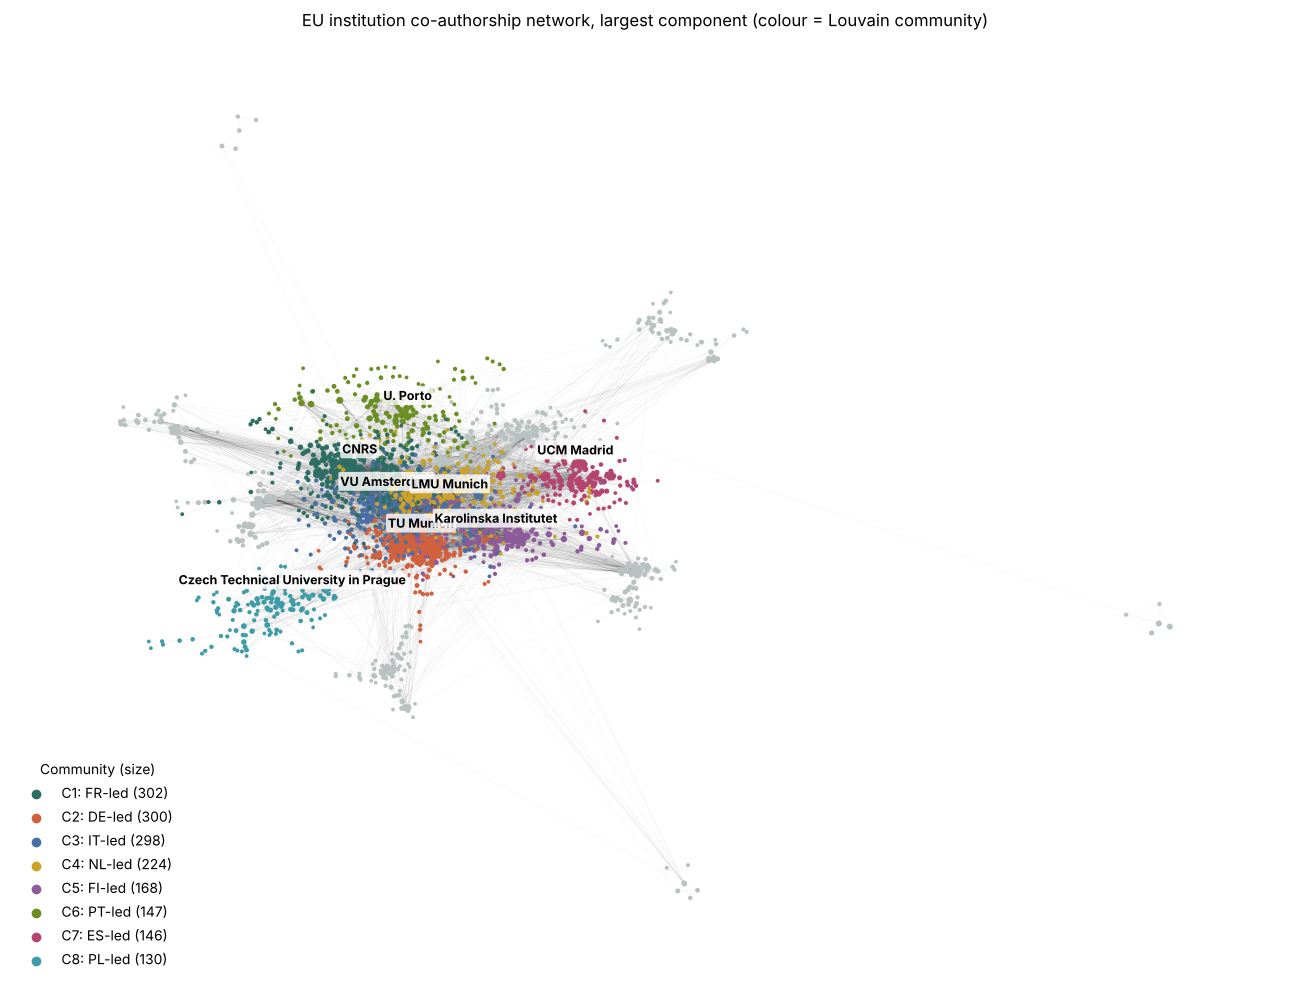

In [8]:
palette = ["#2C6E63", "#D1603D", "#4A6FA5", "#C9A227", "#8E5B9A", "#6B8E23", "#B5446E", "#3D9CA8"]
order = sorted(com, key=len, reverse=True)
col = {}
for i, c in enumerate(order):
    for n in c: col[n] = palette[i] if i < len(palette) else "#B8C2C0"
# Layout: communities placed on a quotient graph, nodes spread inside their own community
lab = {n: i for i, c in enumerate(order) for n in c}
Q = nx.Graph()
Q.add_nodes_from(range(len(order)))
for u, v, d in H.edges(data=True):
    a_, b_ = lab[u], lab[v]
    if a_ != b_: Q.add_edge(a_, b_, weight=Q.get_edge_data(a_, b_, {"weight": 0})["weight"] + d["weight"])
centers = nx.spring_layout(Q, weight="weight", k=3.0, seed=SEED, scale=4.0)
pos = {}
for i, c in enumerate(order):
    sub = H.subgraph(c)
    p = nx.spring_layout(sub, weight="weight", seed=SEED, scale=0.055 * np.sqrt(len(c)) + 0.05) if len(c) > 1 else {next(iter(c)): np.zeros(2)}
    for n, xy in p.items(): pos[n] = centers[i] + xy
size = [5 + 2.5 * np.sqrt(wdeg[n]) for n in H]
fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_edges(H, pos, alpha=0.05, width=0.3, ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=size, node_color=[col[n] for n in H], linewidths=0, ax=ax)
short = {"Centre National de la Recherche Scientifique": "CNRS", "Ludwig-Maximilians-Universität München": "LMU Munich",
         "Technical University of Munich": "TU Munich", "Universidade do Porto": "U. Porto",
         "Universidad Complutense de Madrid": "UCM Madrid", "Vrije Universiteit Amsterdam": "VU Amsterdam"}
for i, c in enumerate(order[:8]):
    hub = max(c, key=lambda n: wdeg[n])
    ax.annotate(short.get(iname[hub], iname[hub]), pos[hub], fontsize=9, weight="bold", ha="center",
                xytext=(0, 12), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
for i, c in enumerate(order[:8]):
    ax.scatter([], [], color=palette[i], label=f"C{i+1}: {Counter(country[n] for n in c).most_common(1)[0][0]}-led ({len(c)})")
ax.legend(title="Community (size)", loc="lower left", frameon=False)
ax.set_title("EU institution co-authorship network, largest component (colour = Louvain community)"); ax.axis("off")
fig.tight_layout(); fig.savefig(OUT / "fig_network_map.png", dpi=200); plt.show()

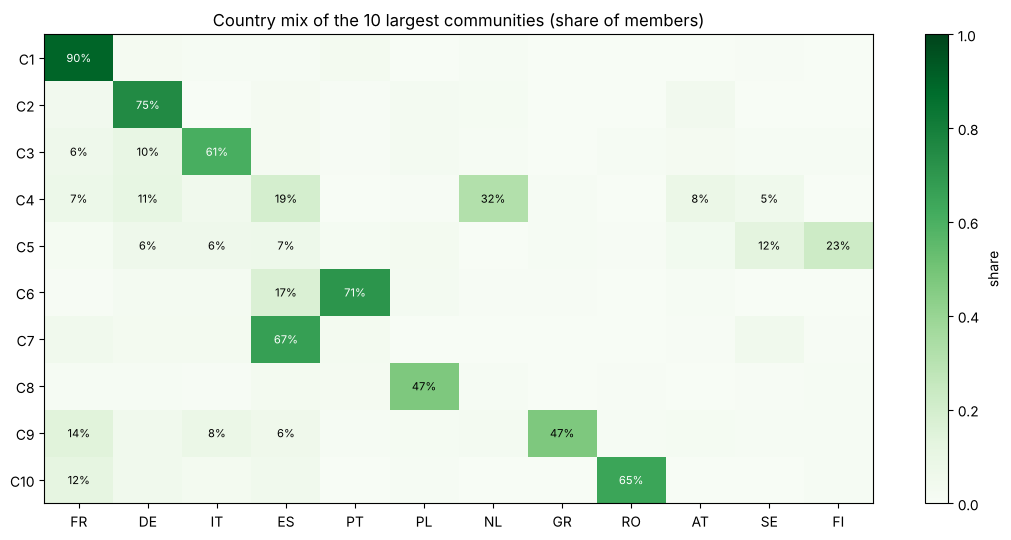

In [9]:
ct = pd.crosstab(cent["community"], cent["country"])
top_countries = ct.sum().sort_values(ascending=False).head(12).index
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index[:10], top_countries]
share = ct.div(cent.groupby("community").size().loc[ct.index], axis=0)
fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(share.values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(share.columns))); ax.set_xticklabels(share.columns)
ax.set_yticks(range(len(share.index))); ax.set_yticklabels([f"C{i}" for i in share.index])
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        if v >= 0.05: ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > .5 else "black")
ax.set_title("Country mix of the 10 largest communities (share of members)"); fig.colorbar(im, ax=ax, label="share")
fig.tight_layout(); fig.savefig(OUT / "fig_community_country.png", dpi=200); plt.show()

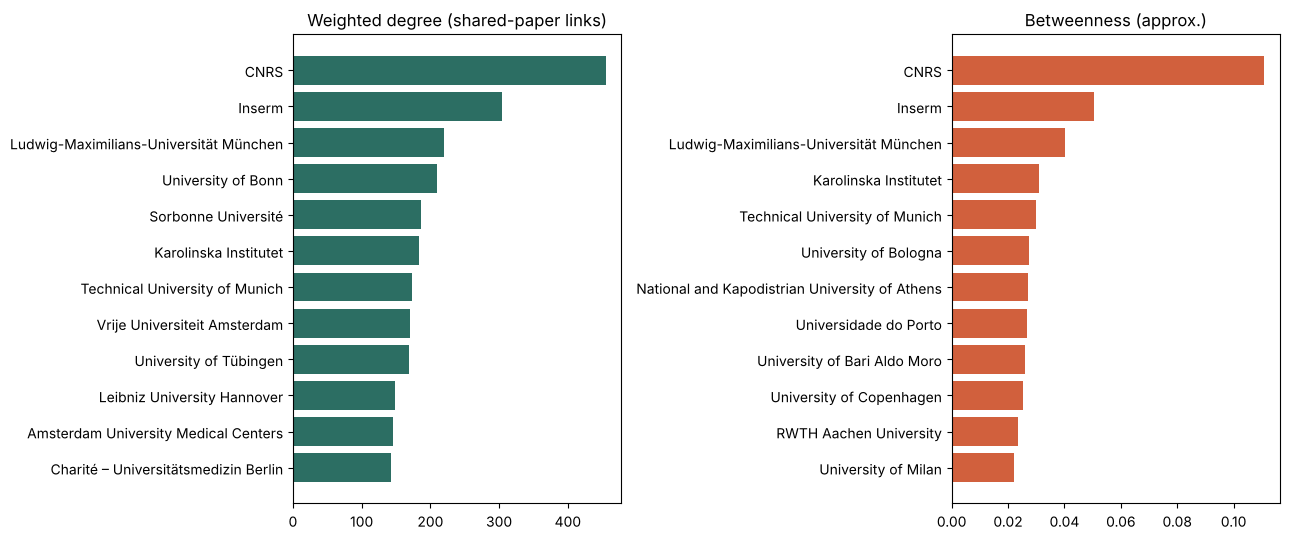

In [10]:
top = cent.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(top.institution.str.replace("Centre National de la Recherche Scientifique", "CNRS"), top.weighted_degree, color="#2C6E63")
axes[0].set_title("Weighted degree (shared-paper links)")
tb = cent.sort_values("betweenness", ascending=False).head(12).iloc[::-1]
axes[1].barh(tb.institution.str.replace("Centre National de la Recherche Scientifique", "CNRS"), tb.betweenness, color="#D1603D")
axes[1].set_title("Betweenness (approx.)")
fig.tight_layout(); fig.savefig(OUT / "fig_centrality.png", dpi=200); plt.show()

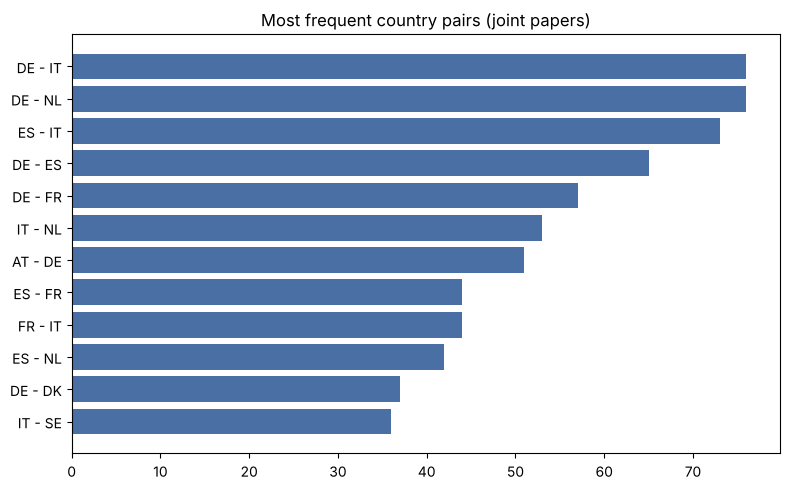

In [11]:
cp10 = cpairs.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cp10.country_a + " - " + cp10.country_b, cp10.joint_papers, color="#4A6FA5")
ax.set_title("Most frequent country pairs (joint papers)"); fig.tight_layout()
fig.savefig(OUT / "fig_country_pairs.png", dpi=200); plt.show()